
# Logistic Regression

## 1. Import Libraries

In [2]:

import pandas as pd
import numpy as np

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt


## 2. Create Dataset

In [3]:

data = {
    'StudyHours': [1, 2, 3, 4, 5, 6],
    'Pass': [0, 0, 0, 1, 1, 1]
}

df = pd.DataFrame(data)

df


,StudyHours,Pass
0,1,0
1,2,0
2,3,0
3,4,1
4,5,1
5,6,1


## 3. Features and Target

In [4]:

X = df[['StudyHours']]
y = df['Pass']

print("Features")
display(X)

print("\nTarget")
display(y)


Features


,StudyHours
0,1
1,2
2,3
3,4
4,5
5,6



Target


0    0
1    0
2    0
3    1
4    1
5    1
Name: Pass, dtype: int64

## 4. Train-Test Split

In [5]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train Shape:", X_train.shape)
print("X_test Shape :", X_test.shape)


X_train Shape: (4, 1)
X_test Shape : (2, 1)



## 5. Feature Scaling

We use StandardScaler to scale the feature values.


In [6]:

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Scaled Training Data")
print(X_train_scaled)


Scaled Training Data
[[ 1.34164079]
 [-1.34164079]
 [ 0.4472136 ]
 [-0.4472136 ]]


## 6. Create Logistic Regression Model

In [7]:

model = LogisticRegression(random_state=42)

model


,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solve

## 7. Train the Model

In [8]:

model.fit(X_train_scaled, y_train)

print("Logistic Regression Model Trained Successfully")


Logistic Regression Model Trained Successfully


## 8. Predictions

In [9]:

predictions = model.predict(X_test_scaled)

print("Predicted Classes")
print(predictions)


Predicted Classes
[0 0]


## 9. Prediction Probabilities

In [10]:

probabilities = model.predict_proba(X_test_scaled)

print(probabilities)


[[0.77589677 0.22410323]
 [0.62927629 0.37072371]]


In [11]:
# model.classes_ returns the list of class labels learned by the model during training.
# The order of these classes determines the column order in: model.predict_proba

# Meaning: If output: [0 1]
# First probability column → class 0
# Second probability column → class 1

print(model.classes_)

[0 1]



## 10. Predict New Student

Predict result for:
Study Hours = 4.5


In [12]:

new_data = [[4.5]]

new_scaled = scaler.transform(new_data)

prediction = model.predict(new_scaled)

probability = model.predict_proba(new_scaled)

print("Predicted Class:", prediction[0])

print("\nPrediction Probability")
print(probability)


Predicted Class: 1

Prediction Probability
[[0.22220112 0.77779888]]


c:\Users\OM\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


## 11. Accuracy Score

In [13]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

accuracy = accuracy_score(y_test, predictions)

print("Accuracy:", accuracy)


Accuracy: 1.0


## 12. Confusion Matrix

In [ ]:

cm = confusion_matrix(y_test, predictions)

print(cm)

cm = confusion_matrix(y_test, predictions, labels=[0, 1])
print(cm)

[[2 0]
 [0 0]]


## 13. Classification Report

In [15]:

report = classification_report(y_test, predictions)

print(report)


              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2

    accuracy                           1.00         2
   macro avg       1.00      1.00      1.00         2
weighted avg       1.00      1.00      1.00         2



## 14. Visualize Dataset

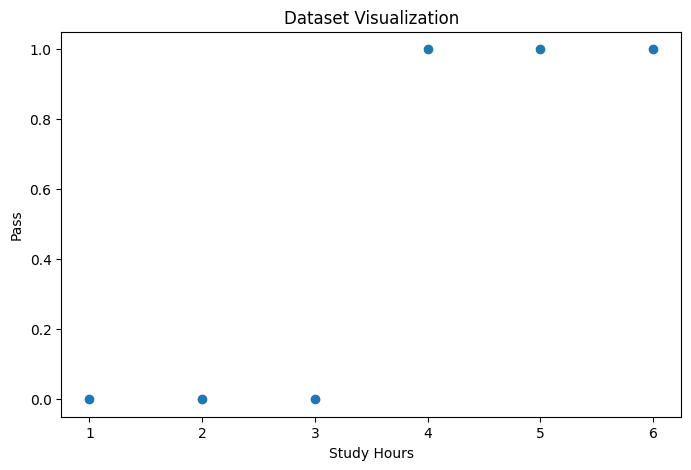

In [16]:

plt.figure(figsize=(8,5))

plt.scatter(X, y)

plt.xlabel("Study Hours")
plt.ylabel("Pass")

plt.title("Dataset Visualization")

plt.show()


## 15. Sigmoid Function Visualization

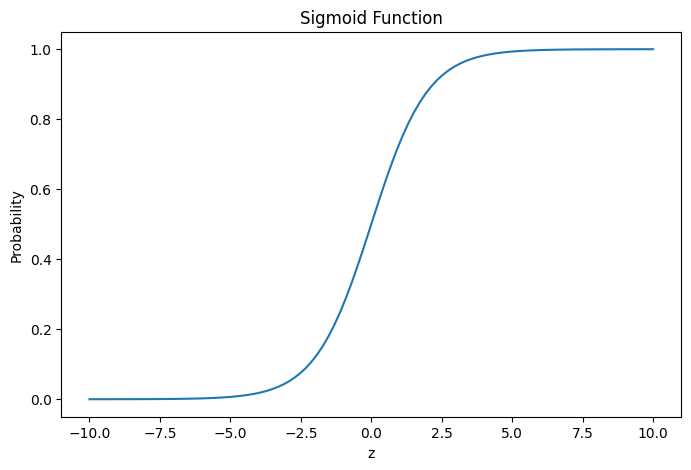

In [17]:

x = np.linspace(-10, 10, 100)

y_sigmoid = 1 / (1 + np.exp(-x))

plt.figure(figsize=(8,5))

plt.plot(x, y_sigmoid)

plt.xlabel("z")
plt.ylabel("Probability")

plt.title("Sigmoid Function")

plt.show()


## 16. Decision Boundary

c:\Users\OM\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


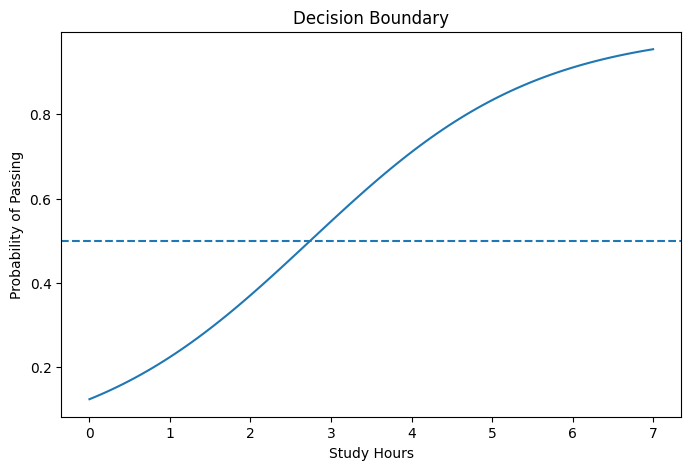

In [18]:

study_hours = np.linspace(0, 7, 100).reshape(-1,1)

study_hours_scaled = scaler.transform(study_hours)

probabilities = model.predict_proba(study_hours_scaled)[:,1]

plt.figure(figsize=(8,5))

plt.plot(study_hours, probabilities)

plt.axhline(y=0.5, linestyle='--')

plt.xlabel("Study Hours")
plt.ylabel("Probability of Passing")

plt.title("Decision Boundary")

plt.show()


## 17. Model Coefficients

In [19]:

print("Coefficient:", model.coef_)

print("Intercept:", model.intercept_)


Coefficient: [[0.79693391]]
Intercept: [1.25288506]



# 18. Final Summary

Logistic Regression:

- Predicts probabilities
- Uses sigmoid function
- Performs binary classification
- Uses decision boundary
- Produces interpretable results


### For more reference: https://youtu.be/jN8-xBel2xk